In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

df = pd.read_csv('fig2_redshift_values.csv')

models = {'naive': 'Naive SFR', 'o_dependent': 'O-dependent', 'fe_dependent': 'Fe-dependent'}
model_colors = {'naive': '#808080', 'o_dependent': '#bf6360', 'fe_dependent': '#377e7f'}
panels = {'Population Total': 'Population', 'ELasTiCC': 'ELAsTiCC', 'Oracle': 'ORACLE'}

df.groupby(['panel', 'model'])[['N', 'N_R0lo', 'N_R0hi']].sum().round(1)

N     N_R0lo      N_R0hi
panel            model                                          
ELasTiCC         fe_dependent    917999.0   565915.7   1509145.3
                 naive           281141.0   173314.0    462182.0
                 o_dependent     466939.0   287852.3    767624.8
Oracle           fe_dependent    790922.5   487577.3   1300237.8
                 naive           243813.4   150302.8    400817.3
                 o_dependent     402596.6   248187.4    661849.1
Population Total fe_dependent  14432797.0  8897337.2  23726809.5
                 naive          2034661.0  1254300.5   3344882.8
                 o_dependent    7033255.0  4335766.8  11562325.8

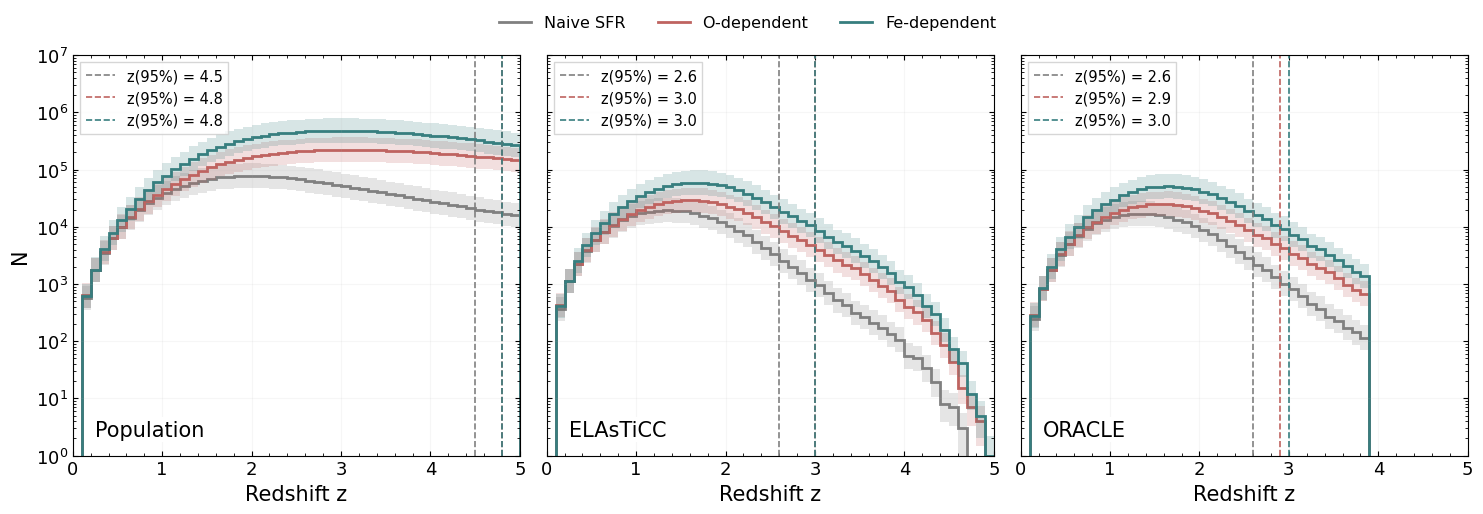

In [2]:
paper_rc = {'font.size': 13, 'axes.labelsize': 15, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
            'legend.fontsize': 11.5, 'legend.title_fontsize': 11.5,
            'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
            'xtick.minor.visible': True, 'ytick.minor.visible': True}

with plt.rc_context(paper_rc):
    fig, axs = plt.subplots(1, 3, figsize=(18, 5.2), sharey=True, gridspec_kw={'wspace': 0.06})
    for ax, (panel, title) in zip(axs, panels.items()):
        for model, color in model_colors.items():
            d = df[(df['model'] == model) & (df['panel'] == panel)].sort_values('z_lo')
            z_edges = np.append(d['z_lo'].values, d['z_hi'].values[-1])
            N = d['N'].values
            z95 = z_edges[1:][np.searchsorted(np.cumsum(N) / N.sum(), 0.95)]
            band_lo = N - np.hypot(N - d['N_R0lo'].values, d['sqrt_N'].values)
            band_hi = N + np.hypot(d['N_R0hi'].values - N, d['sqrt_N'].values)

            ax.stairs(N, z_edges, color=color, lw=2)
            ax.stairs(band_hi, z_edges, baseline=np.clip(band_lo, 1e-3, None), fill=True, color=color, alpha=0.2, lw=0)
            ax.axvline(z95, color=color, ls='--', lw=1.2, label=f'z(95%) = {z95:.1f}')

        ax.set_yscale('log')
        ax.set_ylim(1, 1e7)
        ax.set_xlim(0, 5)
        ax.set_xlabel('Redshift z')
        ax.text(0.05, 0.04, title, transform=ax.transAxes, ha='left', va='bottom', fontsize=15,
                bbox=dict(facecolor='white', edgecolor='none', pad=2))
        ax.grid(alpha=0.1)
        ax.legend(loc='upper left', fontsize=10.5, fancybox=False, facecolor='white')
    axs[0].set_ylabel('N')

    handles = [Line2D([], [], color=c, lw=2) for c in model_colors.values()]
    fig.legend(handles, list(models.values()), loc='lower center', bbox_to_anchor=(0.5, 0.9), ncol=len(handles),
               fancybox=False, facecolor='white', frameon=False)
    plt.savefig('slsn_counts_by_z.pdf', bbox_inches='tight')
    plt.show()